In [9]:
import subprocess
import sys

try:
    import fairlearn
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "fairlearn"])


In [3]:
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate, demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference
from fairlearn.postprocessing import ThresholdOptimizer

# 1. Download and load the dataset
dataset_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
column_names = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country",
    "income"
]

data_path = "adult.csv"
if not os.path.exists(data_path):
    print("Downloading Adult Census Income dataset...")
    urllib.request.urlretrieve(dataset_url, data_path)

df = pd.read_csv(data_path, names=column_names, sep=",\\s*", engine="python")
display(df.head())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [13]:
# 2. Clean and preprocess dataset
df = df.replace("?", np.nan).dropna()

if df['income'].dtype == object:
    df['income'] = df['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)

X = df.drop(columns=['income'])
y = df['income']

sex_series = X['sex']
X_features = X.drop(columns=['sex'])

X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X_features, y, sex_series, test_size=0.30, random_state=42, stratify=y
)

numerical_cols = X_features.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X_features.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Build baseline model pipeline
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Train baseline
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'fnlwgt',
                                                   'education-num',
                                                   'capital-gain',
                                                   'capital-loss',
                                                   'hours-per-week']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['workclass', 'education',
                                                   'marital-status',
                                                   'occupation', 'relationship',
                                                   'race',
                                                   'native-country'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [14]:
# 3. Evaluate Baseline Model & Report Metrics
y_pred_base = model.predict(X_test)

# Overall Accuracy
acc_base = accuracy_score(y_test, y_pred_base)
print(f"Baseline model : Logistic Regression Accuracy : {acc_base:.2f}\n")

metrics_dict = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'tpr': true_positive_rate,
    'fpr': false_positive_rate
}

mf_base = MetricFrame(
    metrics=metrics_dict,
    y_true=y_test,
    y_pred=y_pred_base,
    sensitive_features=sex_test
)

print("GROUP ACCURACY SELECTION_RATE TPR FPR")
print("---------------------------------------------------")
for group in ['Male', 'Female']:
    g_m = mf_base.by_group.loc[group]
    print(f"{group:<8} {g_m['accuracy']:.2f}     {g_m['selection_rate']:.2f}           {g_m['tpr']:.2f} {g_m['fpr']:.2f}")
print("---------------------------------------------------")

dp_diff_base = demographic_parity_difference(y_test, y_pred_base, sensitive_features=sex_test)
dp_ratio_base = demographic_parity_ratio(y_test, y_pred_base, sensitive_features=sex_test)
eo_diff_base = equalized_odds_difference(y_test, y_pred_base, sensitive_features=sex_test)

print(f"Demographic parity difference : {dp_diff_base:.2f}")
print(f"Demographic parity ratio (DI) : {dp_ratio_base:.2f} (< 0.80 -> BIAS if less)")
print(f"Equalized odds difference : {eo_diff_base:.2f}")


Baseline model : Logistic Regression Accuracy : 0.85

GROUP ACCURACY SELECTION_RATE TPR FPR
---------------------------------------------------
Male     0.81     0.26           0.61 0.10
Female   0.92     0.09           0.53 0.03
---------------------------------------------------
Demographic parity difference : 0.17
Demographic parity ratio (DI) : 0.34 (< 0.80 -> BIAS if less)
Equalized odds difference : 0.08


In [6]:
# 4. Mitigation with ThresholdOptimizer: Demographic Parity
to_dp = ThresholdOptimizer(
    estimator=model,
    constraints="demographic_parity",
    predict_method='predict_proba',
    prefit=True
)

to_dp.fit(X_train, y_train, sensitive_features=sex_train)
y_pred_to_dp = to_dp.predict(X_test, sensitive_features=sex_test)

# Evaluate DP model
acc_to_dp = accuracy_score(y_test, y_pred_to_dp)
mf_to_dp = MetricFrame(
    metrics=metrics_dict,
    y_true=y_test,
    y_pred=y_pred_to_dp,
    sensitive_features=sex_test
)
sel_m_dp = mf_to_dp.by_group.loc['Male', 'selection_rate']
sel_f_dp = mf_to_dp.by_group.loc['Female', 'selection_rate']
dp_diff_to_dp = demographic_parity_difference(y_test, y_pred_to_dp, sensitive_features=sex_test)
eo_diff_to_dp = equalized_odds_difference(y_test, y_pred_to_dp, sensitive_features=sex_test)


In [7]:
# 5. Mitigation with ThresholdOptimizer: Equalized Odds
to_eo = ThresholdOptimizer(
    estimator=model,
    constraints="equalized_odds",
    predict_method='predict_proba',
    prefit=True
)

to_eo.fit(X_train, y_train, sensitive_features=sex_train)
y_pred_to_eo = to_eo.predict(X_test, sensitive_features=sex_test)

# Evaluate EO model
acc_to_eo = accuracy_score(y_test, y_pred_to_eo)
mf_to_eo = MetricFrame(
    metrics=metrics_dict,
    y_true=y_test,
    y_pred=y_pred_to_eo,
    sensitive_features=sex_test
)
sel_m_eo = mf_to_eo.by_group.loc['Male', 'selection_rate']
sel_f_eo = mf_to_eo.by_group.loc['Female', 'selection_rate']
dp_diff_to_eo = demographic_parity_difference(y_test, y_pred_to_eo, sensitive_features=sex_test)
eo_diff_to_eo = equalized_odds_difference(y_test, y_pred_to_eo, sensitive_features=sex_test)


MODEL ACC SEL_M SEL_F DP_DIFF EO_DIFF
--------------------------------------------------------------
Baseline             0.85 0.26  0.09  0.17    0.08
TO: demographic_par. 0.83 0.16  0.16  0.00    0.31
TO: equalized_odds   0.84 0.22  0.13  0.09    0.01
--------------------------------------------------------------


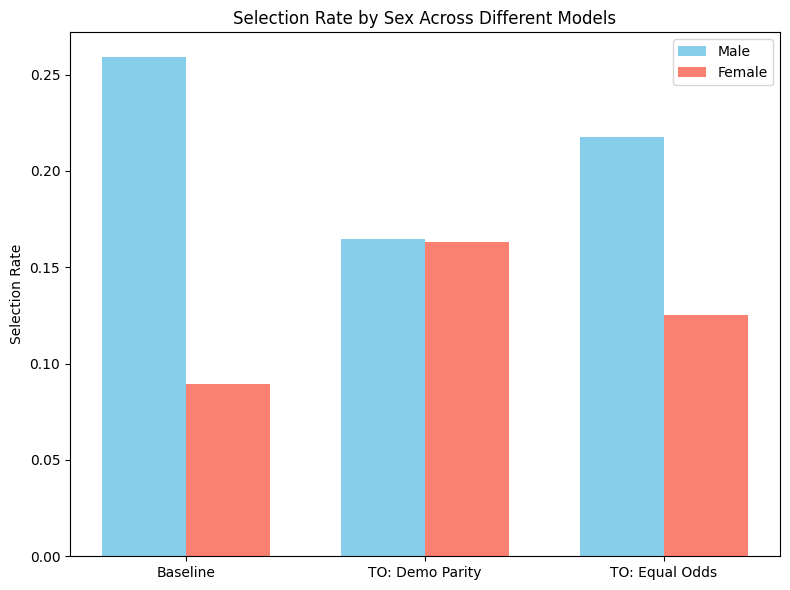

Plot saved : selection_rate_by_sex.png
No single model satisfies both fairness definitions.


In [8]:
# 6. Print Summary Table and Plot Selection Rates
summary_df = pd.DataFrame({
    'MODEL': ['Baseline', 'TO: demographic_par.', 'TO: equalized_odds'],
    'ACC': [acc_base, acc_to_dp, acc_to_eo],
    'SEL_M': [mf_base.by_group.loc['Male', 'selection_rate'], sel_m_dp, sel_m_eo],
    'SEL_F': [mf_base.by_group.loc['Female', 'selection_rate'], sel_f_dp, sel_f_eo],
    'DP_DIFF': [dp_diff_base, dp_diff_to_dp, dp_diff_to_eo],
    'EO_DIFF': [eo_diff_base, eo_diff_to_dp, eo_diff_to_eo]
})

print("MODEL ACC SEL_M SEL_F DP_DIFF EO_DIFF")
print("--------------------------------------------------------------")
for _, row in summary_df.iterrows():
    print(f"{row['MODEL']:<20} {row['ACC']:.2f} {row['SEL_M']:.2f}  {row['SEL_F']:.2f}  {row['DP_DIFF']:.2f}    {row['EO_DIFF']:.2f}")
print("--------------------------------------------------------------")

# Plot selection rate by sex
labels = ['Baseline', 'TO: Demo Parity', 'TO: Equal Odds']
male_rates = [mf_base.by_group.loc['Male', 'selection_rate'], sel_m_dp, sel_m_eo]
female_rates = [mf_base.by_group.loc['Female', 'selection_rate'], sel_f_dp, sel_f_eo]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(x - width/2, male_rates, width, label='Male', color='skyblue')
ax.bar(x + width/2, female_rates, width, label='Female', color='salmon')

ax.set_ylabel('Selection Rate')
ax.set_title('Selection Rate by Sex Across Different Models')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.tight_layout()
plt.savefig('selection_rate_by_sex.png')
plt.show()
print("Plot saved : selection_rate_by_sex.png")
print("No single model satisfies both fairness definitions.")
